In [42]:
!pip install loguru==0.7.2

In [43]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abc import ABC, abstractmethod
from loguru import logger


In [44]:

# ABSTRACT BANDIT CLASS


class Bandit(ABC):

    @abstractmethod
    def __init__(self, p):
        pass

    @abstractmethod
    def __repr__(self):
        pass

    @abstractmethod
    def pull(self):
        pass

    @abstractmethod
    def update(self):
        pass

    @abstractmethod
    def experiment(self):
        pass

    @abstractmethod
    def report(self):
        pass


In [45]:

# EPSILON-GREEDY

class EpsilonGreedy(Bandit):

    def __init__(self, p):
        self.p = np.array(p)
        self.n = len(p)

        # Number of times each advertisement was selected
        self.N = np.zeros(self.n)

        # Estimated AVG reward of each advertisement
        self.Q = np.zeros(self.n)

        self.best_reward = max(p)
        self.precision = 1

        self.selected_arms = []
        self.rewards = []
        self.cumulative_rewards = []
        self.cumulative_regrets = []
        self.history = []

        self.total_reward = 0
        self.total_regret = 0

    def __repr__(self):
        return "Epsilon-Greedy Bandit"

    def pull(self, t):

        epsilon = 1 / t

        if np.random.random() < epsilon:
            arm = np.random.randint(self.n)

        else:
            best_arms = np.flatnonzero(self.Q == self.Q.max())
            arm = np.random.choice(best_arms)

        reward = np.random.normal(
            loc=self.p[arm],
            scale=1 / np.sqrt(self.precision)
        )

        return arm, reward

    def update(self, arm, reward):

        self.N[arm] += 1

        self.Q[arm] += (
            reward - self.Q[arm]
        ) / self.N[arm]

    def experiment(self, trials=20000):

        for t in range(1, trials + 1):

            arm, reward = self.pull(t)

            self.update(arm, reward)

            regret = self.best_reward - self.p[arm]

            self.selected_arms.append(arm + 1)
            self.rewards.append(reward)

            self.total_reward += reward
            self.total_regret += regret

            self.cumulative_rewards.append(self.total_reward)
            self.cumulative_regrets.append(self.total_regret)

            self.history.append(self.Q.copy())

        logger.info("Epsilon-Greedy experiment completed.")

        return pd.DataFrame({
            "Bandit": self.selected_arms,
            "Reward": self.rewards,
            "Algorithm": "Epsilon-Greedy"
        })

    def report(self):

        results = pd.DataFrame({
            "Bandit": self.selected_arms,
            "Reward": self.rewards,
            "Algorithm": "Epsilon-Greedy"
        })

        results.to_csv("epsilon_greedy_results.csv", index=False)

        print("\n--- Epsilon-Greedy Report ---")
        print(f"Cumulative reward: {self.total_reward:.2f}")
        print(f"Cumulative regret: {self.total_regret:.2f}")
        print(f"Average reward: {np.mean(self.rewards):.4f}")
        print(
            f"Average regret: "
            f"{self.total_regret / len(self.rewards):.4f}"
        )


In [46]:
# THOMPSON SAMPLING
# Gaussian rewards with known precision

class ThompsonSampling(Bandit):

    def __init__(self, p):
        self.p = np.array(p)
        self.n = len(p)

        # Prior parameters
        self.prior_mean = np.zeros(self.n)
        self.prior_precision = np.ones(self.n)

        # Posterior parameters
        self.posterior_mean = self.prior_mean.copy()
        self.posterior_precision = self.prior_precision.copy()

        self.N = np.zeros(self.n)
        self.sum_rewards = np.zeros(self.n)

        self.best_reward = max(p)
        self.precision = 1

        self.selected_arms = []
        self.rewards = []
        self.cumulative_rewards = []
        self.cumulative_regrets = []
        self.history = []

        self.total_reward = 0
        self.total_regret = 0

    def __repr__(self):
        return "Thompson Sampling Bandit"

    def pull(self):

        samples = np.random.normal(
            loc=self.posterior_mean,
            scale=1 / np.sqrt(self.posterior_precision)
        )

        arm = np.argmax(samples)

        reward = np.random.normal(
            loc=self.p[arm],
            scale=1 / np.sqrt(self.precision)
        )

        return arm, reward

    def update(self, arm, reward):

        self.N[arm] += 1
        self.sum_rewards[arm] += reward

        self.posterior_precision[arm] = (
            self.prior_precision[arm]
            + self.N[arm] * self.precision
        )

        self.posterior_mean[arm] = (
            self.prior_precision[arm] * self.prior_mean[arm]
            + self.precision * self.sum_rewards[arm]
        ) / self.posterior_precision[arm]

    def experiment(self, trials=20000):

        for t in range(1, trials + 1):

            arm, reward = self.pull()

            self.update(arm, reward)

            regret = self.best_reward - self.p[arm]

            self.selected_arms.append(arm + 1)
            self.rewards.append(reward)

            self.total_reward += reward
            self.total_regret += regret

            self.cumulative_rewards.append(self.total_reward)
            self.cumulative_regrets.append(self.total_regret)

            self.history.append(self.posterior_mean.copy())

        logger.info("Thompson Sampling experiment completed.")

        return pd.DataFrame({
            "Bandit": self.selected_arms,
            "Reward": self.rewards,
            "Algorithm": "Thompson Sampling"
        })

    def report(self):

        results = pd.DataFrame({
            "Bandit": self.selected_arms,
            "Reward": self.rewards,
            "Algorithm": "Thompson Sampling"
        })

        results.to_csv("thompson_sampling_results.csv", index=False)

        print("\n--- Thompson Sampling Report ---")
        print(f"Cumulative reward: {self.total_reward:.2f}")
        print(f"Cumulative regret: {self.total_regret:.2f}")
        print(f"Average reward: {np.mean(self.rewards):.4f}")
        print(
            f"Average regret: "
            f"{self.total_regret / len(self.rewards):.4f}"
        )


In [47]:


# VISUALIZATION

class Visualization:

    def plot1(self, epsilon_greedy, thompson):

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        algorithms = [
            (epsilon_greedy, "Epsilon-Greedy"),
            (thompson, "Thompson Sampling")
        ]

        for row, (algorithm, name) in enumerate(algorithms):

            history = np.array(algorithm.history)
            trials = np.arange(1, len(history) + 1)

            # Linear scale
            ax = axes[row, 0]

            for i in range(algorithm.n):
                ax.plot(
                    trials,
                    history[:, i],
                    label=f"Advertisement {i + 1}"
                )

                ax.axhline(
                    y=algorithm.p[i],
                    linestyle="--",
                    alpha=0.5,
                    label=f"True reward {i + 1}"
                )

            ax.set_title(f"{name} - Linear Scale")
            ax.set_xlabel("Number of Trials")
            ax.set_ylabel("Estimated Average Reward")
            ax.legend()
            ax.grid(True)

            # Logarithmic scale
            ax = axes[row, 1]

            for i in range(algorithm.n):
                ax.plot(
                    trials,
                    history[:, i],
                    label=f"Advertisement {i + 1}"
                )

            ax.axhline(
                y=algorithm.best_reward,
                color="black",
                linestyle="--",
                label="Best true reward"
            )

            ax.set_xscale("log")
            ax.set_title(f"{name} - Logarithmic Scale")
            ax.set_xlabel("Number of Trials (log scale)")
            ax.set_ylabel("Estimated Average Reward")
            ax.legend()
            ax.grid(True)

        plt.tight_layout()
        plt.show()

    def plot2(self, epsilon_greedy, thompson):

        trials = np.arange(
            1, len(epsilon_greedy.rewards) + 1
        )

        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        axes[0].plot(
            trials,
            epsilon_greedy.cumulative_rewards,
            label="Epsilon-Greedy"
        )

        axes[0].plot(
            trials,
            thompson.cumulative_rewards,
            label="Thompson Sampling"
        )

        axes[0].set_title("Cumulative Rewards Comparison")
        axes[0].set_xlabel("Number of Trials")
        axes[0].set_ylabel("Cumulative Reward")
        axes[0].legend()
        axes[0].grid(True)

        # Cumulative regrets
        axes[1].plot(
            trials,
            epsilon_greedy.cumulative_regrets,
            label="Epsilon-Greedy"
        )

        axes[1].plot(
            trials,
            thompson.cumulative_regrets,
            label="Thompson Sampling"
        )

        axes[1].set_title("Cumulative Regret Comparison")
        axes[1].set_xlabel("Number of Trials")
        axes[1].set_ylabel("Cumulative Regret")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()



In [48]:


# COMPARISON

def comparison(epsilon_greedy, thompson):

    visualization = Visualization()

    visualization.plot1(epsilon_greedy, thompson)
    visualization.plot2(epsilon_greedy, thompson)


2026-11-17 18:47:03.696 | INFO     | __main__:experiment:77 - Epsilon-Greedy experiment completed.



--- Epsilon-Greedy Report ---
Cumulative reward: 79734.47
Cumulative regret: 135.00
Average reward: 3.9867
Average regret: 0.0067


2026-11-17 18:47:04.477 | INFO     | __main__:experiment:88 - Thompson Sampling experiment completed.
2026-11-17 18:47:04.710 | INFO     | __main__:<cell line: 0>:28 - Combined CSV file created successfully.



--- Thompson Sampling Report ---
Cumulative reward: 79369.13
Cumulative regret: 598.00
Average reward: 3.9685
Average regret: 0.0299

Combined results:
   Bandit    Reward       Algorithm
0       1  1.543743  Epsilon-Greedy
1       1  0.384570  Epsilon-Greedy
2       1  0.905379  Epsilon-Greedy
3       1  0.071172  Epsilon-Greedy
4       3  2.530526  Epsilon-Greedy

Total observations: 40000

Epsilon-Greedy selections:
[4.0000e+00 1.0000e+00 1.2100e+02 1.9874e+04]

Thompson Sampling selections:
[2.0000e+00 1.0000e+00 5.9000e+02 1.9407e+04]


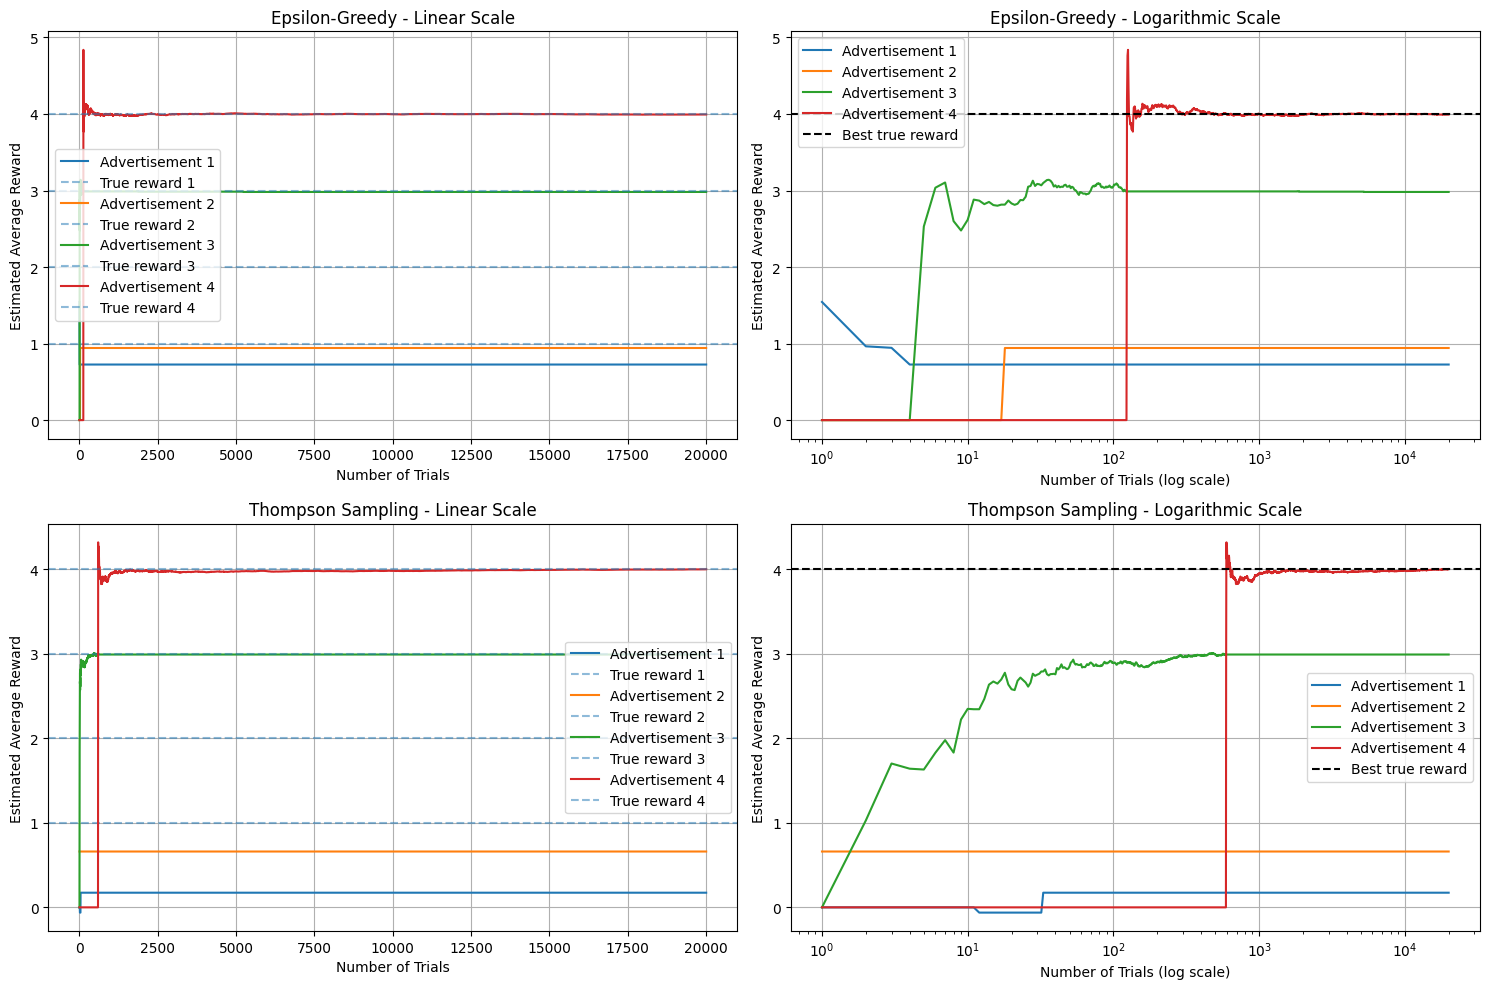

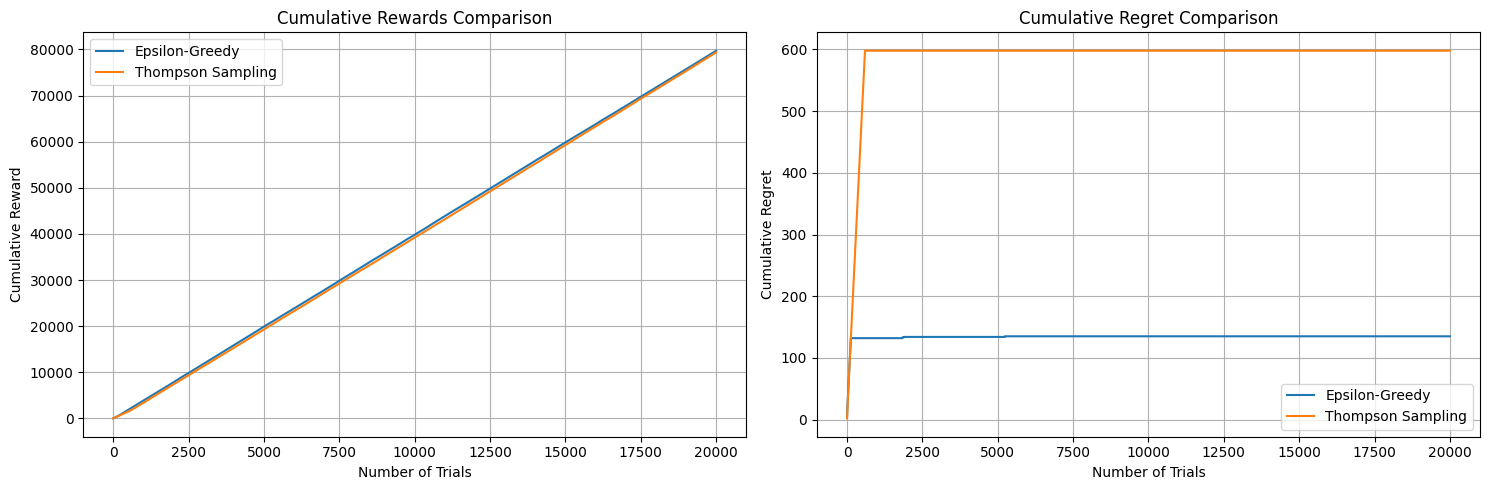

In [49]:


# MAIN EXECUTION

if __name__ == "__main__":

    # Reproducibility
    np.random.seed(42)

    Bandit_Reward = [1, 2, 3, 4]
    NumberOfTrials = 20000

    # Epsilon-Greedy
    epsilon_greedy = EpsilonGreedy(Bandit_Reward)
    epsilon_results = epsilon_greedy.experiment(NumberOfTrials)
    epsilon_greedy.report()

    # Thompson Sampling
    thompson = ThompsonSampling(Bandit_Reward)
    thompson_results = thompson.experiment(NumberOfTrials)
    thompson.report()

    all_results = pd.concat(
        [epsilon_results, thompson_results],
        ignore_index=True
    )

    all_results.to_csv("bandit_results.csv", index=False)

    logger.info("Combined CSV file created successfully.")

    print("\nCombined results:")
    print(all_results.head())
    print(f"\nTotal observations: {len(all_results)}")

    print("\nEpsilon-Greedy selections:")
    print(epsilon_greedy.N)

    print("\nThompson Sampling selections:")
    print(thompson.N)

    comparison(epsilon_greedy, thompson)


In [50]:

# FINAL CHECKS

print("Epsilon-Greedy trials:", len(epsilon_results))
print("Thompson Sampling trials:", len(thompson_results))

print("\nCombined dataset shape:", all_results.shape)

print("\nCSV columns:")
print(all_results.columns.tolist())

print("\nMissing values:")
print(all_results.isnull().sum())

print("\nEpsilon-Greedy selections:")
print(epsilon_greedy.N.astype(int))

print("\nThompson Sampling selections:")
print(thompson.N.astype(int))

print("\nFinal cumulative rewards:")
print("Epsilon-Greedy:", epsilon_greedy.cumulative_rewards[-1])
print("Thompson Sampling:", thompson.cumulative_rewards[-1])

print("\nFinal cumulative regrets:")
print("Epsilon-Greedy:", epsilon_greedy.cumulative_regrets[-1])
print("Thompson Sampling:", thompson.cumulative_regrets[-1])

assert len(epsilon_results) == 20000
assert len(thompson_results) == 20000
assert len(all_results) == 40000
assert all_results.columns.tolist() == [
    "Bandit", "Reward", "Algorithm"
]
assert all_results.isnull().sum().sum() == 0

print("\nSUCCESS: All final checks passed!")


Epsilon-Greedy trials: 20000
Thompson Sampling trials: 20000

Combined dataset shape: (40000, 3)

CSV columns:
['Bandit', 'Reward', 'Algorithm']

Missing values:
Bandit       0
Reward       0
Algorithm    0
dtype: int64

Epsilon-Greedy selections:
[    4     1   121 19874]

Thompson Sampling selections:
[    2     1   590 19407]

Final cumulative rewards:
Epsilon-Greedy: 79734.46937194657
Thompson Sampling: 79369.12853061211

Final cumulative regrets:
Epsilon-Greedy: 135
Thompson Sampling: 598

SUCCESS: All final checks passed!


In [51]:
import os

print("Generated CSV files:")

for file in [
    "epsilon_greedy_results.csv",
    "thompson_sampling_results.csv",
    "bandit_results.csv"
]:
    print(file, "->", os.path.exists(file))

Generated CSV files:
epsilon_greedy_results.csv -> True
thompson_sampling_results.csv -> True
bandit_results.csv -> True


In [52]:
from google.colab import files

files.download("bandit_results.csv")
files.download("epsilon_greedy_results.csv")
files.download("thompson_sampling_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Suggested Better Implementation Plan
Here I compared Epsilon-Greedy and Thompson Sampling with four ads and 20,000 trials. Both algorithms find the best ad, but we could make the experiment better in a few ways.
1. Run the experiment many times
We only ran each algorithm one time. It would be better to repeat it with different random seeds and take the average of the cumulative reward and the cumulative regret. One run can be lucky or unlucky, so the average gives a fairer comparison.
2. Add confidence intervals
We can show confidence intervals around the average results for both algorithms. This shows how stable each algorithm is from one run to another.
3. Try different exploration settings
For Epsilon-Greedy, we can test different epsilon values and also try decaying epsilon (so it explores less over time). Then we can see how much the exploration rate changes the results.
4. Use real ad data
Our rewards are made up from Normal distributions. Next time we could use real data like clicks or conversions, so the experiment is closer to a real marketing campaign.
5. Try contextual bandits
We could also use customer info like age group, device, or location. Then the algorithm picks the ad based on who the user is, not just one best ad for everyone.

Conclusion
These changes would make the results more reliable, give a better comparison between the two algorithms, and make the experiment more like real marketing.